# 3 · Signalling and gene regulation at genome scale

**What is known genome-wide:** which protein acts on which, and with what sign (OmniPath: literature-curated),
and which transcription factor regulates which gene (CollecTRI). **What is not:** rate constants.

So this layer is a signed network linearised around the growing reference state. Edge weights follow
literature support, a hand-curated backbone of 208 textbook edges dominates the input of its targets, and the
overall gain is set from the leading eigenvalue so the reference state is stable. It predicts **directions and
relative sizes** of pathway responses, not absolute kinetics. That is the honest fidelity level of this layer.

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from humancell import data, plotting as P; P.style()
from humancell.signaling import Signaling

g = data.build_gene_table("HeLa")
sig = Signaling(g)
pd.Series({"signalling proteins": sig.n, "expressed in HeLa": int(sig.expressed.sum()), "signed interactions": len(sig.edges),
           "curated backbone interactions": int(sig.edges.core.sum()), "transcription factors": len(sig.tfs),
           "TF → gene interactions": len(sig.reg), "genes with ≥1 regulator": int((sig.R.getnnz(axis=1) > 0).sum()),
           "network gain β": round(sig.beta, 2), "regulatory gain": round(sig.gain, 2)}, name="value").to_frame()

,value
signalling proteins,5144.00
expressed in HeLa,3751.00
signed interactions,14475.00
curated backbone interactions,208.00
transcription factors,1163.00
TF → gene interactions,42900.00
genes with ≥1 regulator,6502.00
network gain β,4.80
regulatory gain,0.28


## Pathway responses
Each column is one stimulus or inhibitor applied to the resting network; colour is the log2 change in activity.

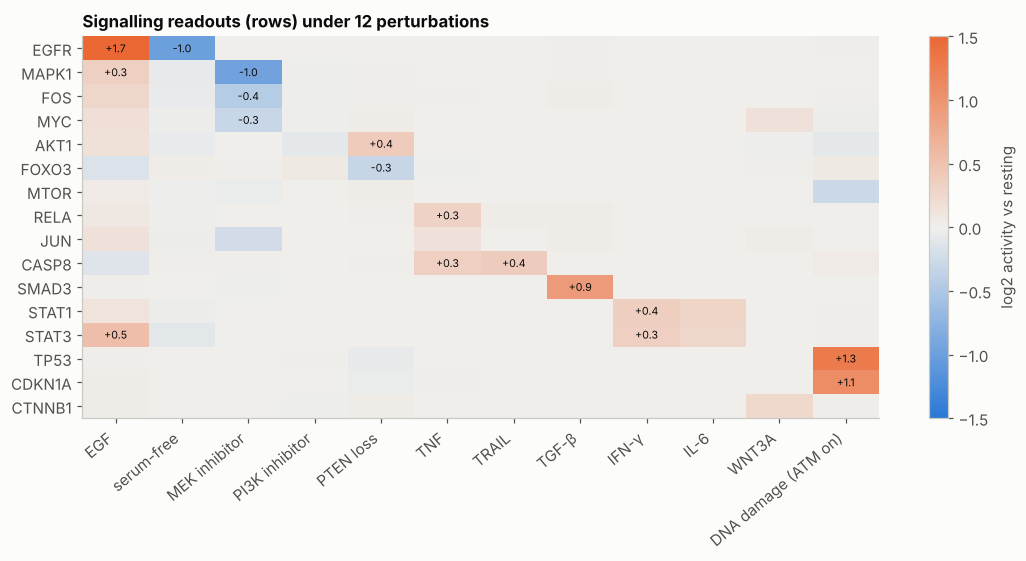

,EGF,serum-free,MEK inhibitor,PI3K inhibitor,PTEN loss,TNF,TRAIL,TGF-β,IFN-γ,IL-6,WNT3A,DNA damage (ATM on)
genes whose transcription rate changes > 1.25×,113,9,99,0,3,6,0,61,3,0,1,598


In [2]:
readouts = ["EGFR", "MAPK1", "FOS", "MYC", "AKT1", "FOXO3", "MTOR", "RELA", "JUN", "CASP8", "SMAD3", "STAT1", "STAT3", "TP53", "CDKN1A", "CTNNB1"]
ones = np.ones(sig.n)

def respond(clamp=None, off=(), serum=None):
    sig.a, sig.clamp = sig.a_ref.copy(), {}
    if serum is not None: sig.serum(serum)
    if clamp: sig.set(**clamp)
    av = ones.copy()
    for s in off: av[sig.pos[s]] = 0.03
    for _ in range(80): sig.step(av)
    act = pd.Series({r: np.log2(max(sig.activity(r), 1e-3)) for r in readouts})
    n_genes = int((np.abs(np.log2(sig.regulation(np.ones(len(g))))) > np.log2(1.25)).sum())
    sig.a, sig.clamp = sig.a_ref.copy(), {}
    return act, n_genes

conds = {"EGF": dict(clamp={"EGF": 1.0}), "serum-free": dict(serum=0.0), "MEK inhibitor": dict(off=["MAP2K1", "MAP2K2"]),
         "PI3K inhibitor": dict(off=["PIK3CA"]), "PTEN loss": dict(off=["PTEN"]), "TNF": dict(clamp={"TNF": 1.0}),
         "TRAIL": dict(clamp={"TNFSF10": 1.0}), "TGF-β": dict(clamp={"TGFB1": 1.0}), "IFN-γ": dict(clamp={"IFNG": 1.0}),
         "IL-6": dict(clamp={"IL6": 1.0}), "WNT3A": dict(clamp={"WNT3A": 1.0}), "DNA damage (ATM on)": dict(clamp={"ATM": 1.0})}
res = {k: respond(**v) for k, v in conds.items()}
M = pd.DataFrame({k: v[0] for k, v in res.items()})
cmap = LinearSegmentedColormap.from_list("div", [P.SERIES[0], "#f0efec", P.SERIES[1]])
fig, ax = plt.subplots(figsize=(10, 5.2))
im = ax.imshow(M.values, cmap=cmap, vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=40, ha="right")
ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index); ax.grid(False)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if abs(M.values[i, j]) >= 0.3: ax.text(j, i, f"{M.values[i, j]:+.1f}", ha="center", va="center", fontsize=7, color=P.INK)
fig.colorbar(im, ax=ax, label="log2 activity vs resting"); ax.set_title("Signalling readouts (rows) under 12 perturbations")
plt.tight_layout(); plt.show()
pd.Series({k: v[1] for k, v in res.items()}, name="genes whose transcription rate changes > 1.25×").to_frame().T

**Reading the map.** The textbook wiring comes out with the right signs: EGF raises ERK/FOS/MYC and AKT and
lowers FOXO3; MEK inhibition does the reverse on the ERK arm only; PTEN loss raises AKT; TNF drives NF-κB,
JUN and caspase-8; TGF-β, IFN-γ, IL-6 and WNT each hit their own effector; ATM activates p53 and p21.

**Limits.** Magnitudes are modest and uniform because weights are not fitted. Cross-talk beyond the curated
backbone is diluted. The natural next step is to learn the weights from perturbation data while keeping this
topology, which is exactly the hybrid direction the 2025 Virtual Cell Challenge pointed to.